We attempt to calculate $\chi$

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import numpy as np
from scipy.integrate import cumulative_trapezoid

In [2]:
"""
Compute   I = int_0^{Tg} dotOmega_x(t) * cos(theta(t)) dt
with       theta(t) = int_0^{t} Omega_x(tau) dtau

Pulse functions are reproduced verbatim from the user-provided definitions.
"""

# ----------------------------------------------------------------------
# Pulse definitions (verbatim from the prompt)
# ----------------------------------------------------------------------
def Omega_x(t, args):
    """Real part of the pulse: truncated Gaussian (main DRAG amplitude)."""
    for item, p in args.items():
        if item == 'clock':
            continue
        if t <= p['start'] or t >= (p['start'] + p['tg']):
            continue
        t_local = t - p['start']
        gauss   = np.exp(-(t_local - p['tg']/2)**2 / (2*p['sigma']**2))
        offset  = np.exp(-p['tg']**2 / (8*p['sigma']**2))
        return p['A'] * (gauss - offset) / (1 - offset)
    return 0


def dotOmega_x(t, args):
    """Imaginary part / DRAG correction."""
    for item, p in args.items():
        if item == 'clock':
            continue
        if t <= p['start'] or t >= (p['start'] + p['tg']):
            continue
        t_local = t - p['start']
        tg, sigma, A = p['tg'], p['sigma'], p['A']

        norm   = 1 - np.exp(-tg**2 / (8*sigma**2))
        gauss  = np.exp(-(t_local - tg/2)**2 / (2*sigma**2))
        offset = np.exp(-tg**2 / (8*sigma**2))

        G  = A * (gauss - offset) / norm
        dG = -A * (t_local - tg/2) / sigma**2 * gauss / norm

        # Raised-cosine window: enforces zero endpoints
        w  = 0.5 * (1 - np.cos(2*np.pi*t_local/tg))
        dw = (np.pi/tg) * np.sin(2*np.pi*t_local/tg)
        return (dG * w + G * dw)
    return 0


# ----------------------------------------------------------------------
# Parameters
# ----------------------------------------------------------------------
Tg    = 20.0          # ns
sigma = 5.0           # ns
A     = 0.23900      # = 0.2512 * i
lambda_j = 0.621
Delta_2 = -2 * np.pi * 0.3071

args = {
    'pulse': {'start': 0.0, 'tg': Tg, 'sigma': sigma, 'A': A, 'beta': 0.0},
}


# ----------------------------------------------------------------------
# Numerical integration on a uniform grid
#   theta via cumulative trapezoid, outer integral via trapezoid.
#   Arrays are complex (A is imaginary), numpy handles this transparently.
# ----------------------------------------------------------------------
def compute(N):
    t   = np.linspace(0.0, Tg+20, N)
    Ox  = np.array([Omega_x(ti, args)    for ti in t], dtype=complex)
    dOx = np.array([dotOmega_x(ti, args) for ti in t], dtype=complex)

    theta     = lambda_j*cumulative_trapezoid(Ox, t, initial=0.0)   # theta(t)
    integrand = dOx * np.cos(theta)                         # sin of complex arg
    return lambda_j*np.trapezoid(integrand, t)/Delta_2


# Convergence check: refine the grid until the value is stable.
for N in (2_001, 4_001, 8_001, 16_001, 32_001):
    val = compute(N)
    print(f"N = {N:>6d}   I = {val.real:+.10e} {val.imag:+.10e}j")

val = compute(32_001)
print()
print(f"Result:  I = {val:.8e}")
print(f"         |I| = {abs(val):.8e}")

N =   2001   I = -4.9844753402e-02 -0.0000000000e+00j
N =   4001   I = -4.9844804137e-02 -0.0000000000e+00j
N =   8001   I = -4.9844816820e-02 -0.0000000000e+00j
N =  16001   I = -4.9844819991e-02 -0.0000000000e+00j


N =  32001   I = -4.9844820784e-02 -0.0000000000e+00j

Result:  I = -4.98448208e-02-0.00000000e+00j
         |I| = 4.98448208e-02


In [3]:
0.0503, 0.0498, 4.984*1e-2, 5.03*1e-2

(0.0503, 0.0498, 0.04984, 0.050300000000000004)

In [4]:
true_noise = np.load('./data/measured/drape_50pts_-1.0_-0.2_0.2365_asterisk.npz')
artificial_noise = np.load('./data/simulated/drape/0.2512/drape_sim_500pts_-2.0_0.1_0.2512_k1to21.npz')

In [5]:
true_noise, artificial_noise

(NpzFile './data/measured/drape_50pts_-1.0_-0.2_0.2365_asterisk.npz' with keys: beta_swept, drape_pops, y_fit_pops,
 NpzFile './data/simulated/drape/0.2512/drape_sim_500pts_-2.0_0.1_0.2512_k1to21.npz' with keys: beta_range, drape_pops, y_fit)

In [6]:
artificial_noise['y_fit'].shape

(21, 500, 4)

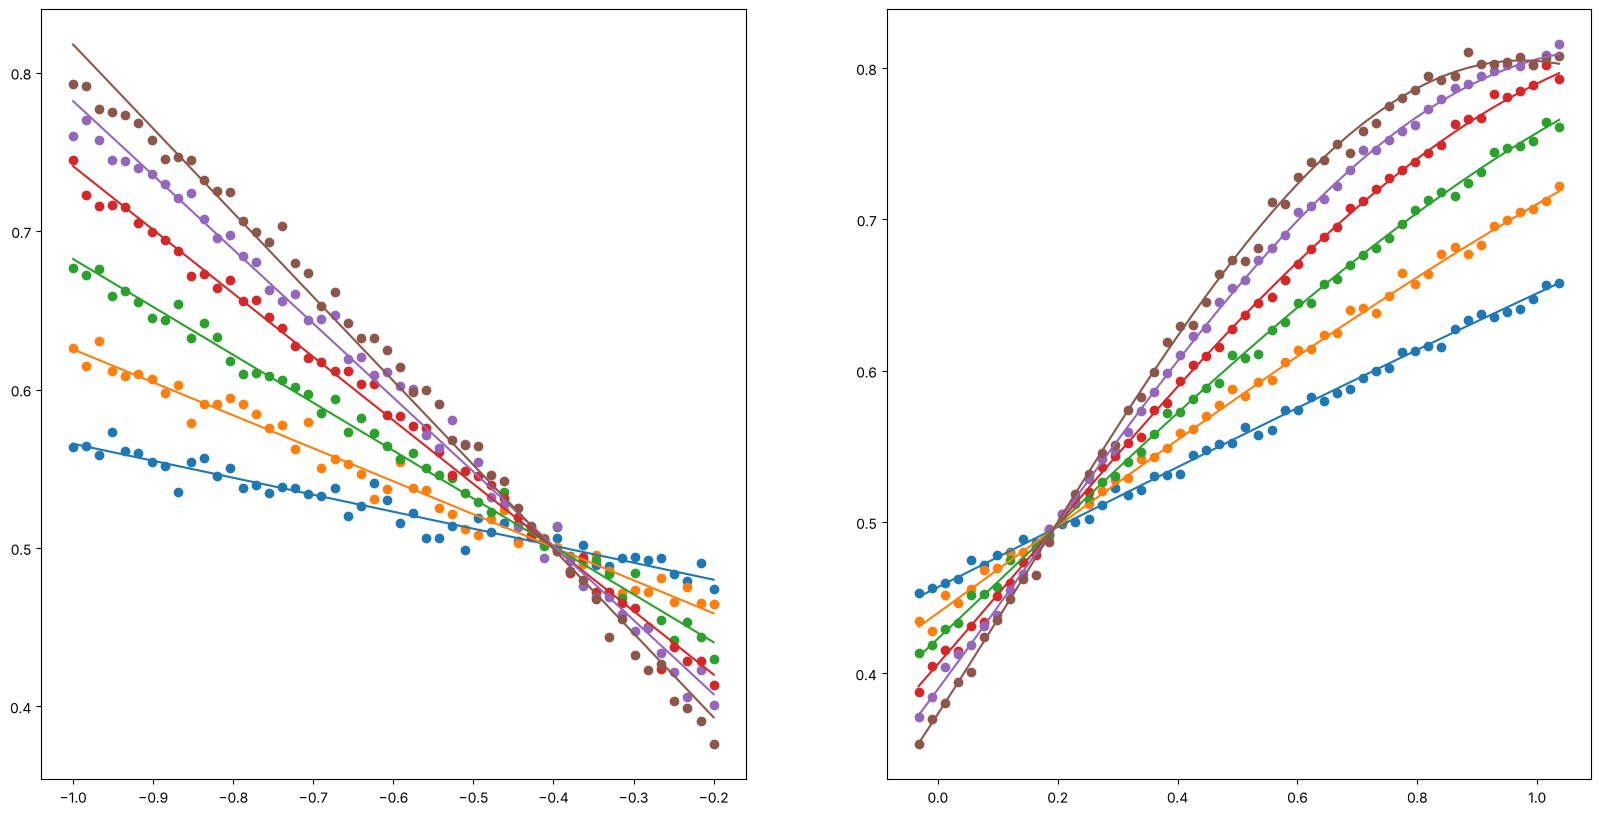

In [7]:
import matplotlib.pyplot as plt 

fig, axes = plt.subplots(ncols=2,figsize=(20, 10))
for i in range(6):
    axes[0].scatter(true_noise['beta_swept'], true_noise['drape_pops'][i][:, 2])
    axes[0].plot(true_noise['beta_swept'], true_noise['y_fit_pops'][i])

for i in range(6):
    axes[1].scatter(artificial_noise['beta_range'][::10], artificial_noise['drape_pops'][i][:, 2][::10])
    axes[1].plot(artificial_noise['beta_range'][::10], artificial_noise['y_fit'][i][:,2][::10])